# PEMFC — polarisation physique et vieillissement fondé sur la littérature

Ce notebook construit le modèle de la pile à $70\,^{\circ}\mathrm{C}$ ($343{,}15$ K) en trois étapes séparées :

$$\text{polarisation initiale}\rightarrow\text{lois de vieillissement (littérature)}\rightarrow U(I,t)\rightarrow t_{\mathrm{EoL}}\rightarrow m_{H_2}(t)\ \text{sur le WLTP}.$$

Aucune constante n'est ajustée pour obtenir une durée de vie donnée : le coefficient de transfert provient de Gerling et al. (2022) et Vetter et Schumacher (2019), le courant équivalent de pertes d'hydrogène du bilan de masse mesuré, et les constantes de vieillissement de Colombo et al. (2023). La durée de vie est un **résultat**, confronté ensuite aux durées publiées (DOE 2016 : 4 100 h sur route ; objectif DOE : 8 000 h).

> **Statut dans l'étude.** L'étude retient trois cas de vieillissement : **optimiste** et **central** = modèle linéaire (objectifs et statut du DOE) ; **pessimiste** = modèle par mécanismes. Les résultats de l'étude sont calculés dans `AB_vieillissement_trois_cas`.
>
> Ce notebook calcule le modèle par mécanismes. Seul son scénario « Pessimiste » correspond à un cas de l'étude. Pour la pile, les scénarios « Optimiste » (cellule B) et « Moyen » restent des analyses de l'annexe S8. Pour l'électrolyseur, les jeux « Optimiste » et « Moyen » ne sont plus utilisés : ils mêlaient l'activité de l'anode (plateau 10,4/93, temps 1,0 kh) et sa capacité (plateau 0,49, temps 1,1 kh), qui sont deux grandeurs différentes.

## 0. Fichiers d'entrée

Cette cellule prépare les fichiers de mesures dont le notebook a besoin, dans le dossier du notebook. Il n'y a rien à faire : exécutez-la simplement.

- Si un fichier est déjà là, il est gardé.
- Sinon, il est pris dans le dossier `data/` du dépôt (si le notebook est dans `h2-ageing-lca/notebooks/`), ou téléchargé depuis le dépôt GitHub public (connexion internet nécessaire).

In [ ]:
BESOINS = ['signaux_fuel_cell_1.xlsx', 'mirai2_fuel_cell_trip.xlsx']

import json, shutil, urllib.request
from pathlib import Path
import pandas as pd

DEPOT_EN_LIGNE = "https://raw.githubusercontent.com/Ayabh12/h2-ageing-lca/main/"
ICI = Path.cwd()

def source(chemin):
    """Chemin local dans le dépôt si disponible, sinon adresse sur GitHub."""
    for base in (ICI.parent, ICI.parent / "h2-ageing-lca", ICI / "h2-ageing-lca"):
        if (base / chemin).exists():
            return str(base / chemin)
    return DEPOT_EN_LIGNE + chemin

def copier(chemin, nom):
    src = source(chemin)
    if src.startswith(("http://", "https://", "file:")):
        urllib.request.urlretrieve(src, ICI / nom)
    else:
        shutil.copy(src, ICI / nom)

def preparer(nom, fabrication):
    if (ICI / nom).exists():
        print(f"déjà présent : {nom}")
    else:
        fabrication()
        print(f"préparé      : {nom}")

def _signaux():
    sig = pd.read_csv(source("data/measurements/mirai2_fuel_cell_signals.csv"))
    sig.columns = ["Temps (s)", "Vitesse (km/h)", "Courant FC (A)", "Tension FC (V)", "Niveau hydrogène restant (%)"]
    sig.to_excel(ICI / "signaux_fuel_cell_1.xlsx", index=False)

def _trajet():
    trip = pd.read_csv(source("data/measurements/mirai2_fuel_cell_trip.csv"))
    trip.columns = ["Temps (s)", "Courant FC (A)", "Tension FC (V)"]
    trip.to_excel(ICI / "mirai2_fuel_cell_trip.xlsx", sheet_name="wltp", index=False)

FICHIERS = {
    "signaux_fuel_cell_1.xlsx": _signaux,
    "mirai2_fuel_cell_trip.xlsx": _trajet,
    "profil_electrolyseur_ACV_duree_vie (2).xlsx": lambda: copier("data/measurements/nel_mc250_wind_profile.xlsx", "profil_electrolyseur_ACV_duree_vie (2).xlsx"),
    "pemwe_parametres.json": lambda: copier("data/parameters/pemwe_fit.json", "pemwe_parametres.json"),
    "medium.xlsx": lambda: copier("notebooks/medium.xlsx", "medium.xlsx"),
    "nuc.xlsx": lambda: copier("notebooks/nuc.xlsx", "nuc.xlsx"),
    "wind.xlsx": lambda: copier("notebooks/wind.xlsx", "wind.xlsx"),
    "pv.xlsx": lambda: copier("notebooks/pv.xlsx", "pv.xlsx"),
}
for nom in BESOINS:
    preparer(nom, FICHIERS[nom])

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, brentq, minimize_scalar

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
OUT=Path("resultats_vieillissement_PEMFC_70C");OUT.mkdir(exist_ok=True)
R=8.314462618;F=96485.33212;T_C=70.0;T_K=343.15
N_CELL=330;A_GEO=297.0;   # surface active estimée par Pielecha et Pielecha (2025) : 237 cm² × 1,12 × 1,12
M_H2=2.01588e-3
ALPHA_C=1.0                                  # ORR, Gerling et al. (2022) ; Vetter et Schumacher (2019)
E_REV=1.229-0.85e-3*(T_K-298.15)             # tension réversible à T
print(f"Température : {T_C:.0f} °C ; E_rev(T) = {E_REV:.5f} V")

Température : 70 °C ; E_rev(T) = 1.19075 V


## 1. Données et pertes d'hydrogène mesurées

**Origine.** Cycles de roulage (fichier `signaux_fuel_cell_1.xlsx`, 25 enregistrements à 1 Hz, dont 12 de roulage) et WLTP mesurés sur la Toyota Mirai II du L2EP (Université de Lille), thèse d'A. Alhakim.

**WLTP.** La puissance demandée à chaque seconde est $P_{\mathrm{dem},m}=U_{\mathrm{exp},m}I_{\mathrm{exp},m}$.

**Courant équivalent de pertes d'hydrogène.** Le réservoir de 5,6 kg passe de 56,0 % à 52,5 % pendant le cycle, soit $m_{H_2,\mathrm{obs}}=0{,}196$ kg. La masse faradique du courant externe est inférieure. L'écart regroupe toutes les pertes d'hydrogène non converties en courant (perméation à travers la membrane, purges, imprécision de la jauge) : ce n'est **pas** une mesure directe du crossover. On l'exprime comme un courant équivalent, réparti sur les périodes actives :

$$i_{\mathrm{pertes},0}=\frac{2F\,m_{H_2,\mathrm{obs}}/(N_{\mathrm{cell}}M_{H_2})-\sum_m I_m\Delta t_m}{A_{\mathrm{geo}}T_{\mathrm{actif}}}.$$

Dans le code, la variable garde le nom `I_CROSS_0`. Ce courant n'intervient que dans le **bilan d'hydrogène** ; il n'est pas ajouté au courant électrochimique dans l'équation de tension, faute de pouvoir séparer la part qui traverse réellement la membrane.


In [2]:
CHEMIN_WINDOWS=Path("mirai2_fuel_cell_trip.xlsx")
nom="mirai2_fuel_cell_trip.xlsx"
cands=[CHEMIN_WINDOWS,Path.cwd()/nom,Path.cwd()/"upload"/nom]
fichier=next((x for x in cands if x.exists()),None)
if fichier is None:raise FileNotFoundError("Indiquez le chemin du fichier WLTP dans CHEMIN_WINDOWS.")
df=pd.read_excel(fichier,sheet_name="wltp")
for c in ["Temps (s)","Courant FC (A)","Tension FC (V)"]:df[c]=pd.to_numeric(df[c],errors="coerce")
df[["Temps (s)","Courant FC (A)","Tension FC (V)"]]=df[["Temps (s)","Courant FC (A)","Tension FC (V)"]].interpolate(limit_direction="both")
t_s=df["Temps (s)"].to_numpy(float);I_EXP=df["Courant FC (A)"].to_numpy(float);U_EXP=df["Tension FC (V)"].to_numpy(float)
dt=np.diff(t_s,append=t_s[-1]+np.median(np.diff(t_s)));actif=I_EXP>0;P_DEM=I_EXP*U_EXP

M_H2_OBS=(0.560-0.525)*5.6
T_ACTIF=float(np.sum(dt[actif]));Q_EXP=float(np.sum(I_EXP*dt))
M_H2_FARADAY=N_CELL*M_H2*Q_EXP/(2*F)
I_CROSS_0=(2*F*M_H2_OBS/(N_CELL*M_H2)-Q_EXP)/(A_GEO*T_ACTIF)
print(f"WLTP : {len(df)} points, {dt.sum():.1f} s, puissance maximale = {P_DEM.max()/1000:.2f} kW, T_actif = {T_ACTIF:.0f} s")
print(f"H2 mesuré = {M_H2_OBS:.4f} kg ; H2 faradique = {M_H2_FARADAY:.5f} kg ; courant équivalent de pertes H2 = {I_CROSS_0:.6f} A/cm²")

WLTP : 2033 points, 2032.9 s, puissance maximale = 95.87 kW, T_actif = 1641 s
H2 mesuré = 0.1960 kg ; H2 faradique = 0.19236 kg ; courant équivalent de pertes H2 = 0.002165 A/cm²


## 2. Polarisation initiale

**Choix fondés sur la littérature.**

- Oxydation de l'hydrogène : réaction très rapide (Durst et al., 2014 ; Gerling et al., 2022) ; la perte anodique est négligée.
- Réduction de l'oxygène : loi de Tafel avec $\alpha_c=1$ (Gerling et al., 2022 ; Vetter et Schumacher, 2019).
- Tension réversible : $E_{\mathrm{rev}}(T)=1{,}229-0{,}85\cdot10^{-3}(T-298{,}15)$.
- Le courant équivalent de pertes d'hydrogène n'entre pas dans l'équation de tension (voir section 1).

$$V=E_{\mathrm{rev}}(T)-\frac{RT}{\alpha_cF}\ln\frac{j}{i_{0,c}}-jR_{\mathrm{tot}}+B_c\ln\left(1-\frac{j}{i_{\lim}}\right).$$

$i_{0,c}$ (effectif : il inclut la rugosité et la pression d'oxygène), $R_{\mathrm{tot}}$, $B_c$ et $i_{\lim}$ sont ajustés par moindres carrés bornés avec 200 initialisations, sur les médianes des points quasi stationnaires des 12 cycles de roulage ($I\\ge30$ A, $|\\Delta I|/I<10\\,\\%$ d'une seconde à l'autre, 18 classes de courant de 30 à 610 A ; méthode du notebook `Fitting_polarisation_Mirai_II`, qui donne aussi les intervalles de confiance). $R_{\\mathrm{tot}}$, $B_c$ et $i_{\\lim}$ sont fortement corrélés : seule la courbe est bien déterminée, pas chacun des trois. $R_{\mathrm{tot}}$ est une résistance apparente : elle regroupe la membrane, les contacts et une partie des pertes de transport.


12 cycles de roulage ; 8349 points quasi stationnaires (I >= 30 A) ; 18 classes de courant
  34 A : activation cathode =  332.0 mV ; ohmique =   5.3 mV ; concentration =   1.3 mV
 300 A : activation cathode =  396.3 mV ; ohmique =  46.7 mV ; concentration =  15.3 mV


,Paramètre,Valeur,Unité,Statut
0,E_rev(T),1.190750,V/cell,littérature
1,alpha_c,1.000000,-,littérature
2,"i0,c",0.000002,A/cm2,ajusté
3,"R_tot,0",0.046228,ohm.cm2,ajusté
4,B_c,0.026459,V,ajusté
5,i_lim,2.301800,A/cm2,ajusté
6,"i_pertes,0 (bilan H2)",0.002165,A/cm2,mesure
7,RMSE,0.001986,V/cell,
8,MAE,0.001713,V/cell,
9,R2,0.998875,-,


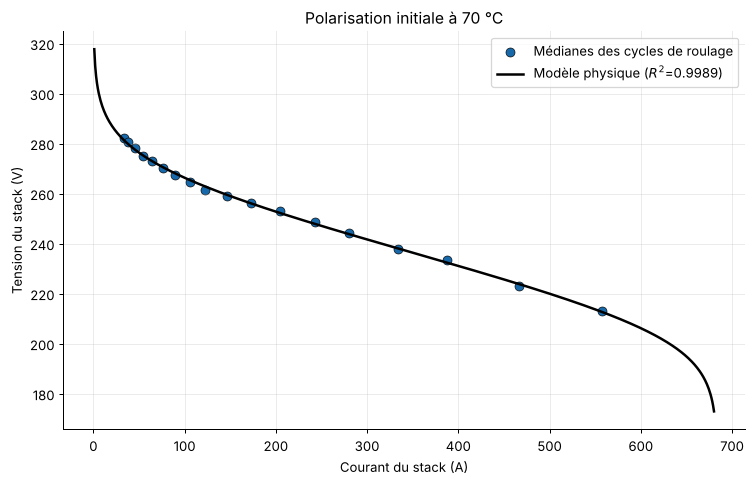

In [3]:
# Courbe de polarisation : médianes des points quasi stationnaires des cycles de roulage (même méthode que le notebook Fitting_polarisation_Mirai_II)
nom_sig="signaux_fuel_cell_1.xlsx"
cands=[Path("signaux_fuel_cell_1.xlsx"),Path.cwd()/nom_sig,Path.cwd()/"signaux_fuel_cell 1.xlsx"]
fsig=next((x for x in cands if x.exists()),None)
if fsig is None:raise FileNotFoundError("Indiquez le chemin de signaux_fuel_cell_1.xlsx.")
sig=pd.read_excel(fsig).rename(columns={"Temps (s)":"t","Vitesse (km/h)":"v","Courant FC (A)":"I","Tension FC (V)":"U","Niveau hydrogène restant (%)":"H2"})
sig["enr"]=np.r_[0,np.cumsum(np.diff(sig.t.to_numpy())<0)]
ROULAGE=sig.groupby("enr").v.max().pipe(lambda x:x.index[x>0]).tolist()
roul=sig[sig.enr.isin(ROULAGE)].copy()
def _stable(g,tol=0.10):
    I=g.I.to_numpy();ok=np.zeros(len(I),bool);ok[1:]=np.abs(I[1:]-I[:-1])/np.maximum(I[1:],1.0)<tol;return pd.Series(ok,index=g.index)
roul["stable"]=roul.groupby("enr",group_keys=False).apply(_stable)
pts=roul[(roul.I>=30.0)&roul.stable]
BORNES=np.unique(np.round(np.geomspace(30.0,610,19)))
POL=pts.groupby(pd.cut(pts.I,BORNES),observed=True).agg(I=("I","median"),U=("U","median"),n=("U","size"),n_cycles=("enr","nunique"))
POL=POL[(POL.n>=5)&(POL.n_cycles>=2)].reset_index(drop=True)
I_POL=POL.I.to_numpy(float);U_POL=POL.U.to_numpy(float)
print(f"{len(ROULAGE)} cycles de roulage ; {len(pts)} points quasi stationnaires (I >= 30 A) ; {len(POL)} classes de courant")
J_POL=I_POL/A_GEO;V_POL=U_POL/N_CELL

def tension_fit(j,theta):
    log_i0c,Rt,Bc,ilim=theta
    return E_REV-R*T_K/(ALPHA_C*F)*np.log(j/10**log_i0c)-j*Rt+Bc*np.log(1-j/ilim)
lo=np.array([-12,0,0,2.03]);hi=np.array([-1,.3,.3,6]);rng=np.random.default_rng(1);best=None
for _ in range(200):
    s=least_squares(lambda x:tension_fit(J_POL,x)-V_POL,rng.uniform(lo,hi),bounds=(lo,hi),max_nfev=5000)
    if best is None or s.cost<best.cost:best=s
LOG_I0C,R_TOT_0,B_C,I_LIM=best.x;I0_C_0=10**LOG_I0C

def metr(e):return np.sqrt(np.mean(e**2)),np.mean(abs(e)),1-np.sum(e**2)/np.sum((V_POL-V_POL.mean())**2)
RMSE,MAE,R2=metr(best.fun)


param_init=pd.DataFrame({"Paramètre":["E_rev(T)","alpha_c","i0,c","R_tot,0","B_c","i_lim","i_pertes,0 (bilan H2)","RMSE","MAE","R2"],
 "Valeur":[E_REV,ALPHA_C,I0_C_0,R_TOT_0,B_C,I_LIM,I_CROSS_0,RMSE,MAE,R2],
 "Unité":["V/cell","-","A/cm2","ohm.cm2","V","A/cm2","A/cm2","V/cell","V/cell","-"],
 "Statut":["littérature","littérature","ajusté","ajusté","ajusté","ajusté","mesure","","",""]})
display(param_init)
Ig=np.linspace(1,.995*I_LIM*A_GEO,700)
fig,ax=plt.subplots(figsize=(8.5,5.5));ax.scatter(I_POL,U_POL,s=52,color="#1769AA",edgecolor="black",lw=.5,label="Médianes des cycles de roulage")
ax.plot(Ig,N_CELL*tension_fit(Ig/A_GEO,best.x),color="black",lw=2,label=f"Modèle physique ($R^2$={R2:.4f})")
ax.set(xlabel="Courant du stack (A)",ylabel="Tension du stack (V)",title="Polarisation initiale à 70 °C");ax.legend();fig.tight_layout()
fig.savefig(OUT/"01_fitting_initial_70C.png",dpi=220);plt.show()
# Décomposition des pertes à 34 A (courant moyen du WLTP) et 300 A
for I in [34,300]:
    j=I/A_GEO
    print(f"{I:4.0f} A : activation cathode = {1e3*R*T_K/(ALPHA_C*F)*np.log(j/I0_C_0):6.1f} mV ; ohmique = {1e3*j*R_TOT_0:5.1f} mV ; concentration = {-1e3*B_C*np.log(1-j/I_LIM):5.1f} mV")

## 3. Lois de vieillissement et constantes de la littérature

Source : Colombo et al. (2023), *J. Power Sources* 553, 232246 — trois assemblages soumis à 1000 h d'un cycle automobile (ID-FAST). Les cellules B et C ont un vieillissement progressif ; la cellule A a subi une perforation de membrane et n'est pas utilisée.

| Mesure publiée | B | C | Constante du modèle |
|---|---|---|---|
| ECSA normalisée à 1000 h | 0,65 | 0,67 | $S(1000\ \mathrm{h})$, qui fixe $k$ |
| Crossover, facteur en 1000 h | 1,4 | 2,6 | $x$, d'où $k_{\mathrm{mem}}=\ln(x)/1000$ |
| Perte de tension à 1,8 A/cm² (1000 h) | 27 mV | 45 mV | $r=\dfrac{\Delta V_{1,8}-\frac{RT}{\alpha_cF}\ln(1/S)}{1{,}8\times1000}$ |
| Résistance de membrane (HFR) | constante | constante | — |

**Perte d'ECSA** : loi de Verducci et al. (Applied Energy 427, 2027, 128742, éq. 8), établie par la même équipe sur le même cycle ID-FAST et le même type d'assemblage (0,1/0,5 mgPt/cm², membrane de 18 µm). Chez Verducci et al., la loi est écrite par cycle équivalent en créneau ($dS/dN=-k^*S^2e^{\omega^*S}$, $k^*_{SC}=3{,}1\times10^{-6}$, $\omega^*=3{,}6$), le cycle ID-FAST d'environ une heure étant décomposé en 10 sous-cycles. Ici, la loi est utilisée sous forme **temporelle effective** : $k$ (en h$^{-1}$) est calé pour reproduire l'ECSA mesurée à 1000 h. Contrôle : $k\approx10\,k^*_{SC}$ par heure, soit $3{,}1\times10^{-5}$ h$^{-1}$, compris entre les valeurs calées pour B et C ($3{,}21$ et $2{,}79\times10^{-5}$ h$^{-1}$). Les facteurs correctifs de Verducci et al. (température, humidité, profil de tension) ne sont pas réappliqués : le profil de vieillissement reste celui de l'essai ID-FAST.

$$\frac{dS}{dt}=-k\,S^2e^{\omega S},\qquad \omega=3{,}6\ (\text{plage }3\text{–}4),\qquad f_A(t)=S(t),\qquad i_{0,c}(t)=i_{0,c,0}f_A(t).$$

$k$ est calibré pour que $S(1000\ \mathrm{h})$ égale l'ECSA mesurée par Colombo et al. Cette loi traduit le mûrissement d'Ostwald : chute rapide au début, puis baisse lente, linéaire en $\ln t$, sans plateau. Une exponentielle à plateau (« premier ordre ») n'est pas cohérente avec les observations selon Verducci et al.
$$R_{\mathrm{tot}}(t)=R_{\mathrm{tot},0}+r\,t=R_{\mathrm{tot},0}(1+k_Rt),\quad k_R=r/R_{\mathrm{tot},0}.$$

**Crossover.** Il part de $i_{x,0}=2$ mA/cm² (spécification DOE d'une membrane neuve) et seule sa hausse s'ajoute à l'écart d'hydrogène mesuré : $i_{\mathrm{pertes}}(t)=i_{\mathrm{écart}}+i_x(t)-i_{x,0}$. Trois lois passent par la même mesure de Colombo et al. (facteur $x$ en 1 000 h) :

| Loi | $i_x(t)$ | Statut |
|---|---|---|
| Linéaire | $i_{x,0}\,[1+(x-1)\,t/1000]$ | **centrale (V13)** : reste sous le seuil DOE de 15 mA/cm² jusqu'à la fin de vie |
| Exponentielle | $i_{x,0}\,e^{k_{\mathrm{mem}}t}$ | comparaison ; forme de Jouin et al. (2016) ; dépasse 15 mA/cm² en fin de vie (moyen, pessimiste) |
| Constante | $i_{x,0}$ | comparaison ; crossover stable mesuré par Toyota (Takahashi et al., IJHE 2022) |

Aucune source ne fixe la forme au-delà de 1 000 h ; les trois lois sont comparées à la section 5 bis.

La résistance de membrane mesurée (HFR) étant constante, Colombo et al. attribuent la perte à fort courant à la cinétique (surface de platine) et au transport de l'oxygène. On retire de la perte mesurée à 1,8 A/cm² la perte cinétique calculée par la loi de Tafel ; le reste (transport) est représenté par une résistance apparente $r\,t$, linéaire en temps (Jouin et al., 2016). La différence entre fort et faible courant est gardée en sensibilité (`r_app_diff`). Le scénario optimiste reprend B, le pessimiste C, le moyen la moyenne des constantes.

In [4]:
COLOMBO={"B":{"S_min":.65,"x_ratio":1.4,"dV_low":7e-3,"dV_high":27e-3},
         "C":{"S_min":.67,"x_ratio":2.6,"dV_low":22e-3,"dV_high":45e-3}}
# V16 : décomposition de Colombo et al. (2023) : HFR constante, perte cinétique liée à la surface de platine (Tafel),
# reste de la perte mesurée à 1,8 A/cm² = transport de l'oxygène, représenté par une résistance linéaire (Jouin et al.).
def r_app(c):
    dv_cin=R*T_K/(ALPHA_C*F)*np.log(1./c["S_min"])     # perte cinétique due à la surface de platine
    return (c["dV_high"]-dv_cin)/1.8/1000.             # reste à 1,8 A/cm², par 1000 h
def r_app_diff(c):  # ancienne méthode (sensibilité) : différence entre fort et faible courant
    return (c["dV_high"]-c["dV_low"])/(1.8-0.08)/1000.
OMEGA=3.6   # Verducci et al. (2027), tableau 3 : omega* entre 3 et 4
def depuis_cellule(c):
    return {"S1000":c["S_min"],"omega":OMEGA,"k_R":r_app(c)/R_TOT_0,"k_mem":np.log(c["x_ratio"])/1000.}
_TAB={}
def table_G(w):
    # g(S) = intégrale de S à 1 de exp(-w s)/s² ds ; t(S) = g(S)/k
    if w not in _TAB:
        S=np.linspace(1.,.02,6000);f=np.exp(-w*S)/S**2
        _TAB[w]=(S,np.concatenate([[0.],np.cumsum(.5*(f[1:]+f[:-1])*(S[:-1]-S[1:]))]))
    return _TAB[w]
def k_ecsa(p):
    S,g=table_G(p["omega"]);return float(np.interp(p["S1000"],S[::-1],g[::-1]))/1000.
scenarios={"Optimiste":depuis_cellule(COLOMBO["B"]),"Pessimiste":depuis_cellule(COLOMBO["C"])}
scenarios["Moyen"]={k:(scenarios["Optimiste"][k]+scenarios["Pessimiste"][k])/2 for k in scenarios["Optimiste"]}
scenarios={k:scenarios[k] for k in ["Optimiste","Moyen","Pessimiste"]}
couleurs={"Optimiste":"#2E8B57","Moyen":"#E69F00","Pessimiste":"#C44E52"}

def activite(t,p):
    if p["S1000"]>=1:return np.ones_like(np.asarray(t,float))
    S,g=table_G(p["omega"]);return np.interp(k_ecsa(p)*np.asarray(t,float),g,S)
def resistance(t,p):return R_TOT_0*(1+p["k_R"]*np.asarray(t))
# Écart mesuré (I_CROSS_0, source inconnue) : constant. Crossover : part de la spécification DOE d'une membrane neuve (2 mA/cm²)
# et croît comme chez Colombo et al. ; seule sa hausse s'ajoute à l'écart mesuré (le crossover initial est compris dans la mesure).
# Trois lois de croissance, calées sur les mêmes mesures de Colombo (facteur x_ratio en 1 000 h) :
#   "lineaire"      : loi centrale (V13) ; reste sous le seuil DOE de 15 mA/cm² jusqu'à la fin de vie ;
#   "exponentielle" : forme de Jouin et al. (2016) ; comparaison ;
#   "constant"      : pas de hausse, comme mesuré par Toyota (Takahashi et al., IJHE 2022) ; comparaison.
I_X0=2e-3
FORME_CROSSOVER="lineaire"
def crossover(t,p,forme=None):   # crossover seul (A/cm²), 2 mA/cm² au départ
    forme=FORME_CROSSOVER if forme is None else forme;t=np.asarray(t,float)
    if forme=="exponentielle":return I_X0*np.exp(p["k_mem"]*t)
    if forme=="lineaire":return I_X0*(1.+(np.exp(p["k_mem"]*1000.)-1.)*t/1000.)
    if forme=="constant":return I_X0+0.*t
    raise ValueError(forme)
def i_cross(t,p):return I_CROSS_0+crossover(t,p)-I_X0   # courant total de pertes H2 (bilan H2 seulement)
def tension_cellule(I,t,p):
    I=np.asarray(I,float);j=np.maximum(I/A_GEO,1e-10)
    if np.any(j>=I_LIM):raise ValueError("j >= i_lim : état hors domaine")
    return (E_REV-R*T_K/(ALPHA_C*F)*np.log(j/(I0_C_0*activite(t,p)))
            -j*resistance(t,p)+B_C*np.log(1-j/I_LIM))
def tension_stack(I,t,p):return N_CELL*tension_cellule(I,t,p)
NEUF={"S1000":1.,"omega":OMEGA,"k_R":0.,"k_mem":0.}
display(pd.DataFrame(scenarios).T.assign(r_mOhm_cm2_kh=lambda d:1e6*d.k_R*R_TOT_0).rename_axis("Scénario"))

,S1000,omega,k_R,k_mem,r_mOhm_cm2_kh
Scénario,,,,,
Optimiste,0.65,3.6,0.000171,0.000336,7.923103
Moyen,0.66,3.6,0.000285,0.000646,13.172031
Pessimiste,0.67,3.6,0.000398,0.000956,18.420959


## 4. Fin de vie

La fin de vie est atteinte quand la tension du stack à $I_{\mathrm{ref}}=300$ A a perdu 10 % : $U(300,t)=0{,}90\,U(300,0)$ (méthode de Brent), critère du DOE pour les stacks automobiles. Le crossover augmente la consommation d'hydrogène mais ne fixe pas la fin de vie. Un critère de membrane (crossover à 15 mA/cm², seuil d'arrêt des essais du DOE) n'est calculé qu'en sensibilité (`eol_membrane`, section 6).


In [5]:
I_REF=300.0;U_REF_0=float(tension_stack(I_REF,0,NEUF));U_SEUIL=.90*U_REF_0
# DOE (conditions de diagnostic) : 2 mA/cm² pour une membrane neuve, arrêt des essais au-delà de 15 mA/cm².
X_NEUF=0.002;X_DEFAIL=0.015;RAPPORT_DEFAIL=X_DEFAIL/X_NEUF
def eol_tension(p,tmax=60000):
    g=lambda t:float(tension_stack(I_REF,t,p)-U_SEUIL)
    return brentq(g,0,tmax) if g(tmax)<=0 else np.nan
def t_crossover(p,seuil,forme=None):   # âge où le crossover atteint « seuil » (A/cm²) ; sensibilité seulement
    forme=FORME_CROSSOVER if forme is None else forme
    if forme=="constant" or p["k_mem"]<=0:return np.inf
    if forme=="exponentielle":return float(np.log(seuil/I_X0)/p["k_mem"])
    return float((seuil/I_X0-1.)*1000./(np.exp(p["k_mem"]*1000.)-1.))
def eol_membrane(p):return t_crossover(p,X_DEFAIL)
def duree_vie(p):return eol_tension(p)   # V12 : fin de vie par la tension (DOE) ; eol_membrane = cas de sensibilité
rows=[]
for nom,p in scenarios.items():
    tv,tm=eol_tension(p),eol_membrane(p);te=tv
    rows.append({"Scénario":nom,"EoL_tension_h":tv,"EoL_membrane_h":tm,"EoL_h":te,"Cause":"tension" if tv<=tm else "pertes H2",
                 "U_300A_EoL_V":float(tension_stack(I_REF,te,p)),"Activité_EOL":float(activite(te,p)),
                 "R_ratio_EOL":float(resistance(te,p)/R_TOT_0),"i_cross_EOL_A_cm2":float(i_cross(te,p))})
resultats=pd.DataFrame(rows).set_index("Scénario");display(resultats.round(5))
print(f"U(300 A, 0) = {U_REF_0:.3f} V ; seuil = {U_SEUIL:.3f} V")
print("Références : DOE (2016) meilleure flotte sur route 4 100 h ; objectif DOE 8 000 h.")

U(300 A, 0) = 241.698 V ; seuil = 217.528 V
Références : DOE (2016) meilleure flotte sur route 4 100 h ; objectif DOE 8 000 h.


,EoL_tension_h,EoL_membrane_h,EoL_h,Cause,U_300A_EoL_V,Activité_EOL,R_ratio_EOL,i_cross_EOL_A_cm2
Scénario,,,,,,,,
Optimiste,5807.95279,16250.0000,5807.95279,tension,217.52843,0.40456,1.99544,0.00681
Moyen,3827.89673,7159.5491,3827.89673,tension,217.52843,0.47024,2.09071,0.00912
Pessimiste,2894.51639,4062.5000,2894.51639,tension,217.52843,0.51918,2.15341,0.01143


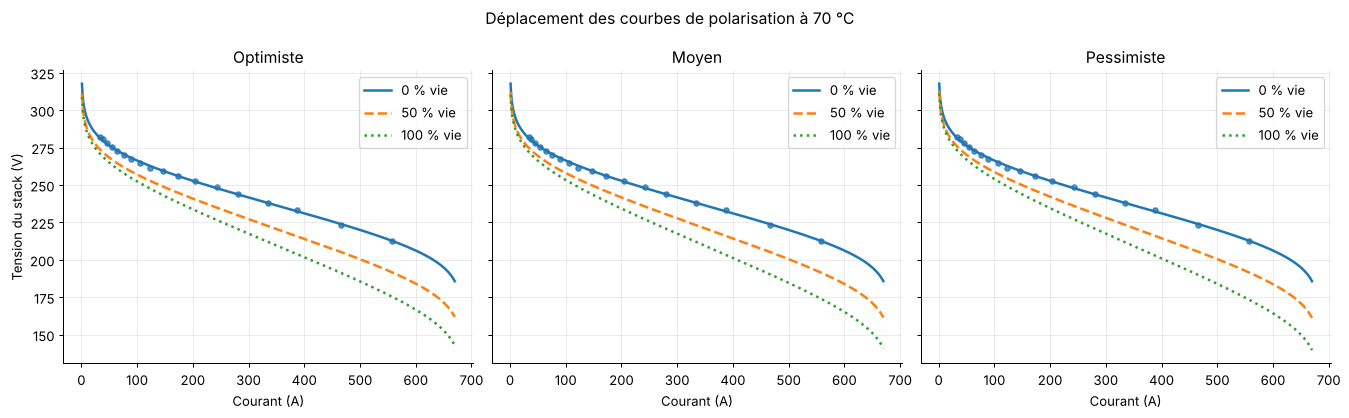

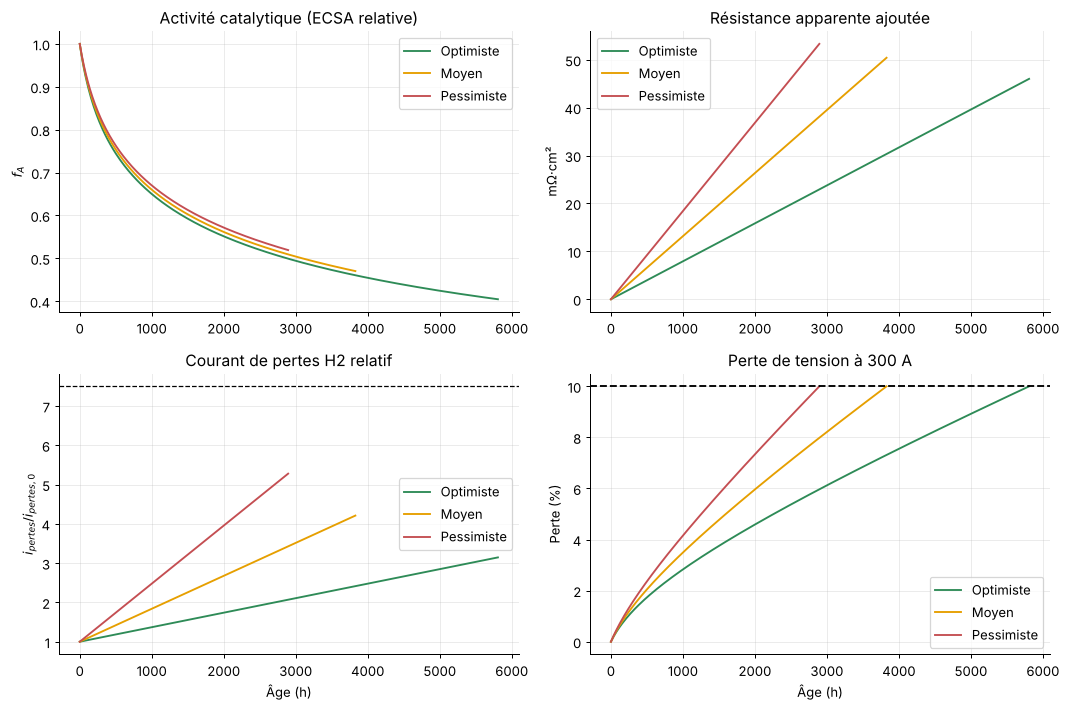

In [6]:
Ig=np.linspace(1,.98*I_LIM*A_GEO,600)
fig,axs=plt.subplots(1,3,figsize=(15,4.7),sharey=True)
for ax,(nom,p) in zip(axs,scenarios.items()):
    te=resultats.loc[nom,"EoL_h"]
    for frac,ls in [(0,"-"),(.5,"--"),(1,":")]:
        ax.plot(Ig,tension_stack(Ig,frac*te,p),ls=ls,lw=2,label=f"{frac*100:.0f} % vie")
    ax.scatter(I_POL,U_POL,s=18,color="#1769AA",alpha=.7);ax.set_title(nom);ax.set_xlabel("Courant (A)");ax.legend()
axs[0].set_ylabel("Tension du stack (V)");fig.suptitle("Déplacement des courbes de polarisation à 70 °C")
fig.tight_layout();fig.savefig(OUT/"02_polarisation_vieillie.png",dpi=220);plt.show()

fig,axs=plt.subplots(2,2,figsize=(12,8))
for nom,p in scenarios.items():
    te=resultats.loc[nom,"EoL_h"];tt=np.linspace(0,te,301);c=couleurs[nom]
    axs[0,0].plot(tt,activite(tt,p),label=nom,color=c)
    axs[0,1].plot(tt,1e3*(resistance(tt,p)-R_TOT_0),label=nom,color=c)
    axs[1,0].plot(tt,i_cross(tt,p)/I_CROSS_0,label=nom,color=c)
    axs[1,1].plot(tt,100*(1-tension_stack(I_REF,tt,p)/U_REF_0),label=nom,color=c)
axs[0,0].set(title="Activité catalytique (ECSA relative)",ylabel="$f_A$")
axs[0,1].set(title="Résistance apparente ajoutée",ylabel="mΩ·cm²")
axs[1,0].set(title="Courant de pertes H2 relatif",xlabel="Âge (h)",ylabel="$i_{pertes}/i_{pertes,0}$");axs[1,0].axhline(RAPPORT_DEFAIL,color="black",ls="--",lw=1)
axs[1,1].set(title="Perte de tension à 300 A",xlabel="Âge (h)",ylabel="Perte (%)");axs[1,1].axhline(10,color="black",ls="--")
for ax in axs.flat:ax.legend()
fig.tight_layout();fig.savefig(OUT/"03_mecanismes_vieillissement.png",dpi=220);plt.show()

## 5. Application au cycle WLTP à puissance constante

Un facteur d'ancrage $c_m=U_{\mathrm{exp},m}/U_{\mathrm{mod}}(I_{\mathrm{exp},m},0)$ garantit que le modèle reproduit exactement le courant initial. À l'âge $t$, la dichotomie résout $c_mU_{\mathrm{mod}}(I_m,t)I_m-P_{\mathrm{dem},m}=0$. La masse d'hydrogène est

$$m_{H_2}=\sum_m\frac{N_{\mathrm{cell}}M_{H_2}}{2F}\left[I_m+A_{\mathrm{geo}}i_{\mathrm{pertes}}(t)\right]\Delta t_m ,$$

les pertes n'étant comptées que pendant les pas actifs.

In [7]:
U_MOD0=tension_stack(np.maximum(I_EXP,.1),0,NEUF);C_ANCRAGE=np.ones_like(I_EXP);C_ANCRAGE[actif]=U_EXP[actif]/U_MOD0[actif]
I_DOM_MAX=.995*I_LIM*A_GEO
def puissance_max(t,p):
    s=minimize_scalar(lambda I:-I*float(tension_stack(I,t,p)),bounds=(.1,I_DOM_MAX),method="bounded")
    return -float(s.fun),float(s.x)
def courant_puissance_constante(t,p,n_iter=60):
    _,ipic=puissance_max(t,p);lo=np.full_like(I_EXP,1e-8);hi=np.full_like(I_EXP,ipic)
    ppic=C_ANCRAGE*ipic*tension_stack(ipic,t,p);ok=(~actif)|(P_DEM<=ppic*(1+1e-10))
    for _ in range(n_iter):
        mid=(lo+hi)/2;pmid=C_ANCRAGE*mid*tension_stack(mid,t,p);bas=pmid<P_DEM
        lo=np.where(bas,mid,lo);hi=np.where(bas,hi,mid)
    I=(lo+hi)/2;I[~actif]=0;I[~ok]=np.nan
    return I,ok
def bilan_cycle(t,p):
    I,ok=courant_puissance_constante(t,p)
    if not np.all(ok):return {"I":I,"ok":ok,"H2":np.nan,"Imoy":np.nan,"Imax":np.nan}
    courant_total=I+A_GEO*i_cross(t,p)*actif.astype(float)
    m=float(np.sum(N_CELL*M_H2*courant_total/(2*F)*dt))
    return {"I":I,"ok":ok,"H2":m,"Imoy":float(I[actif].mean()),"Imax":float(I.max())}
print(f"Facteur d'ancrage c_m : P5 = {np.percentile(C_ANCRAGE[actif],5):.3f}, médiane = {np.median(C_ANCRAGE[actif]):.3f}, P95 = {np.percentile(C_ANCRAGE[actif],95):.3f}")
print(f"H2 initial du modèle = {bilan_cycle(0,NEUF)['H2']:.5f} kg (mesure : {M_H2_OBS:.4f} kg)")

Facteur d'ancrage c_m : P5 = 0.754, médiane = 0.994, P95 = 1.014
H2 initial du modèle = 0.19600 kg (mesure : 0.1960 kg)


,EoL_tension_h,EoL_membrane_h,EoL_h,Cause,U_300A_EoL_V,Activité_EOL,R_ratio_EOL,i_cross_EOL_A_cm2,H2_initial_kg_cycle,H2_EOL_kg_cycle,Hausse_H2_EOL_pct,Part_pertes_H2_hausse_pct,I_moyen_EOL_A,I_max_EOL_A,WLTP_faisable_pct
Scénario,,,,,,,,,,,,,,,
Optimiste,5807.95279,16250.0000,5807.95279,tension,217.52843,0.40456,1.99544,0.00681,0.196,0.21584,10.12399,39.34113,36.13212,539.22674,100.0
Moyen,3827.89673,7159.5491,3827.89673,tension,217.52843,0.47024,2.09071,0.00912,0.196,0.21895,11.70922,50.88332,35.99702,547.66386,100.0
Pessimiste,2894.51639,4062.5000,2894.51639,tension,217.52843,0.51918,2.15341,0.01143,0.196,0.22234,13.43770,59.08625,35.90926,554.12192,100.0


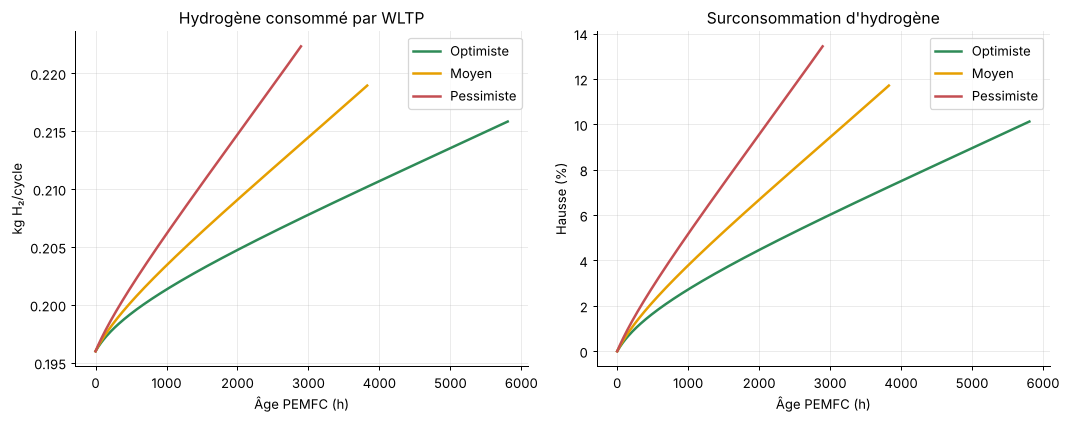

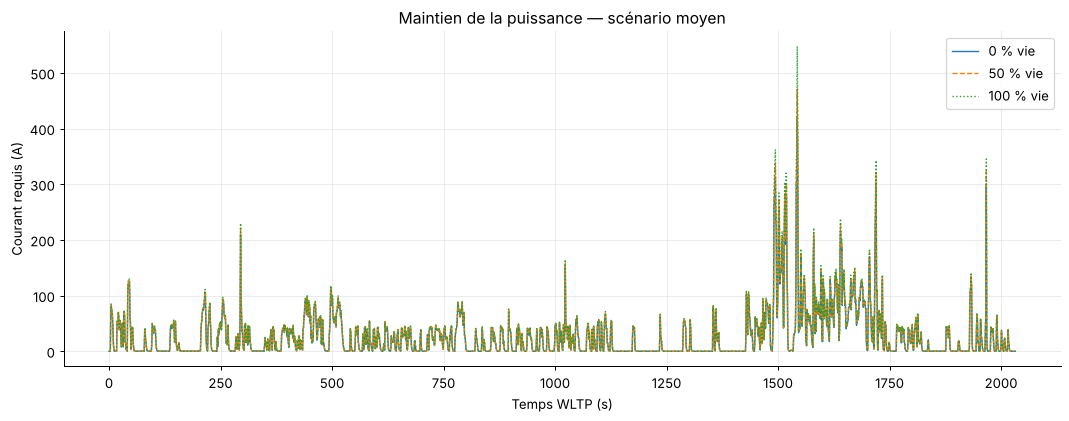

In [8]:
traj={};resume=[]
for nom,p in scenarios.items():
    te=resultats.loc[nom,"EoL_h"];ages=np.linspace(0,te,301);r=[]
    for age in ages:
        b=bilan_cycle(age,p);r.append({"Age_h":age,"H2_kg_cycle":b["H2"],"I_moyen_A":b["Imoy"],"I_max_A":b["Imax"],"Faisabilite":b["ok"].mean(),
                                        "i_cross_A_cm2":float(i_cross(age,p))})
    q=pd.DataFrame(r);traj[nom]=q;h0=q.H2_kg_cycle.iloc[0];he=q.H2_kg_cycle.iloc[-1]
    hx=float(np.sum(N_CELL*M_H2*A_GEO*(i_cross(te,p)-I_CROSS_0)*actif/(2*F)*dt))
    resume.append({"Scénario":nom,"H2_initial_kg_cycle":h0,"H2_EOL_kg_cycle":he,"Hausse_H2_EOL_pct":100*(he/h0-1),
                   "Part_pertes_H2_hausse_pct":100*hx/(he-h0),"I_moyen_EOL_A":q.I_moyen_A.iloc[-1],"I_max_EOL_A":q.I_max_A.iloc[-1],
                   "WLTP_faisable_pct":100*q.Faisabilite.iloc[-1]})
resume=pd.DataFrame(resume).set_index("Scénario");synthese=resultats.join(resume);display(synthese.round(5))

fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for nom,q in traj.items():
    axs[0].plot(q.Age_h,q.H2_kg_cycle,lw=2,label=nom,color=couleurs[nom])
    axs[1].plot(q.Age_h,100*(q.H2_kg_cycle/q.H2_kg_cycle.iloc[0]-1),lw=2,label=nom,color=couleurs[nom])
axs[0].set(title="Hydrogène consommé par WLTP",xlabel="Âge PEMFC (h)",ylabel="kg H₂/cycle")
axs[1].set(title="Surconsommation d'hydrogène",xlabel="Âge PEMFC (h)",ylabel="Hausse (%)")
for ax in axs:ax.legend()
fig.tight_layout();fig.savefig(OUT/"04_hydrogene_WLTP.png",dpi=220);plt.show()

p=scenarios["Moyen"];te=resultats.loc["Moyen","EoL_h"];fig,ax=plt.subplots(figsize=(12,4.8))
for frac,ls in [(0,"-"),(.5,"--"),(1,":")]:
    ax.plot(t_s,courant_puissance_constante(frac*te,p)[0],ls=ls,lw=1.1,label=f"{frac*100:.0f} % vie")
ax.set(xlabel="Temps WLTP (s)",ylabel="Courant requis (A)",title="Maintien de la puissance — scénario moyen");ax.legend()
fig.tight_layout();fig.savefig(OUT/"05_courant_WLTP.png",dpi=220);plt.show()

## 5 bis. Comparaison des lois de crossover

Les trois lois partent du même crossover (2 mA/cm²) et passent par la même mesure à 1 000 h ; seule l'extrapolation change. La fin de vie (tension) ne dépend pas du crossover ; la consommation d'hydrogène, si.


,Loi,Scénario,EoL_h,Crossover_EoL_mA_cm2,H2_EOL_kg_cycle,Hausse_H2_EOL_pct
0,Linéaire (centrale),Optimiste,5807.95,6.65,0.22,10.12
1,Linéaire (centrale),Moyen,3827.90,8.95,0.22,11.71
2,Linéaire (centrale),Pessimiste,2894.52,11.26,0.22,13.44
3,Exponentielle (Jouin),Optimiste,5807.95,14.12,0.23,16.53
4,Exponentielle (Jouin),Moyen,3827.90,23.71,0.24,24.36
5,Exponentielle (Jouin),Pessimiste,2894.52,31.78,0.26,31.03
6,Constant (Toyota),Optimiste,5807.95,2.00,0.21,6.14
7,Constant (Toyota),Moyen,3827.90,2.00,0.21,5.75
8,Constant (Toyota),Pessimiste,2894.52,2.00,0.21,5.50


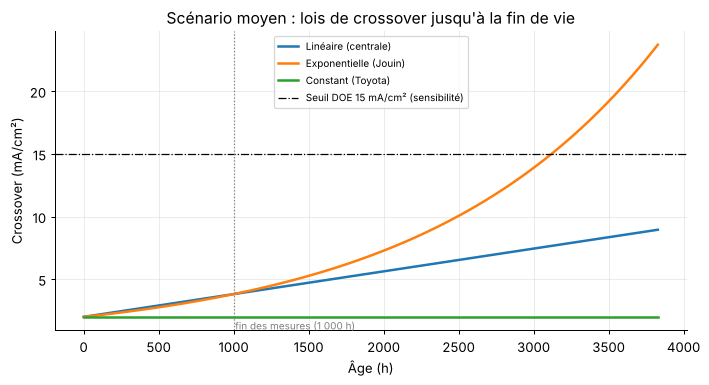

In [9]:
# Comparaison des trois lois de crossover : crossover et hydrogène par WLTP en fin de vie (tension)
FORMES={"lineaire":"Linéaire (centrale)","exponentielle":"Exponentielle (Jouin)","constant":"Constant (Toyota)"}
_forme0=FORME_CROSSOVER;comp=[]
for forme,lab in FORMES.items():
    FORME_CROSSOVER=forme
    for nom,p in scenarios.items():
        te=resultats.loc[nom,"EoL_h"];h0=bilan_cycle(0,p)["H2"];he=bilan_cycle(te,p)["H2"]
        comp.append({"Loi":lab,"Scénario":nom,"EoL_h":te,"Crossover_EoL_mA_cm2":1e3*float(crossover(te,p)),
                     "H2_EOL_kg_cycle":he,"Hausse_H2_EOL_pct":100*(he/h0-1)})
FORME_CROSSOVER=_forme0
comp_x=pd.DataFrame(comp);display(comp_x.round(2))
comp_x.to_csv(OUT/"comparaison_lois_crossover.csv",index=False,encoding="utf-8-sig")
fig,ax=plt.subplots(figsize=(8,4.4));p=scenarios["Moyen"];tt=np.linspace(0,resultats.loc["Moyen","EoL_h"],200)
for forme,lab in FORMES.items():ax.plot(tt,1e3*crossover(tt,p,forme),lw=2,label=lab)
ax.axhline(15,color="k",ls="-.",lw=1,label="Seuil DOE 15 mA/cm² (sensibilité)")
ax.axvline(1000,color="grey",ls=":",lw=1);ax.text(1010,1,"fin des mesures (1 000 h)",fontsize=8,color="grey")
ax.set(xlabel="Âge (h)",ylabel="Crossover (mA/cm²)",title="Scénario moyen : lois de crossover jusqu'à la fin de vie");ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/"05_lois_crossover.png",dpi=220);plt.show()


## 6. Sensibilité : âge où le crossover atteindrait un seuil

Ces âges ne fixent pas la fin de vie (critère de tension). Ils indiquent quand la loi de crossover centrale atteindrait :

- 15 mA/cm² (rapport 7,5), seuil d'arrêt des essais du DOE ;
- 10 mA/cm² (rapport 5), seuil de Jouin et al. (2016) ;
- 3 fois la valeur de départ (15/5 mA/cm² chez Colombo et al., 2023).


In [10]:
def t_mem_cas(p,critere):
    kind,val=critere
    return t_crossover(p,val*I_X0) if kind=="rapport" else t_crossover(p,val)
cas=[("Référence : rapport 7,5 (DOE 15/2)",("rapport",RAPPORT_DEFAIL)),
     ("Rapport 5 (Jouin : 10/2 mA/cm²)",("rapport",5.)),
     ("Rapport 3 (Colombo : 15/5 mA/cm²)",("rapport",3.)),
     ("Seuil absolu 15 mA/cm² en fonctionnement",("absolu",.015))]
lignes=[]
for nom_cas,crit in cas:
    d={"Cas":nom_cas}
    for nom,p in scenarios.items():
        tv=eol_tension(p);tm=t_mem_cas(p,crit);d[f"EoL_{nom}_h"]=min(tv,tm);d[f"cause_{nom}"]="tension" if tv<=tm else "pertes H2"
    lignes.append(d)
sens_crit=pd.DataFrame(lignes);display(sens_crit.round(1))
sens_crit.to_csv(OUT/"sensibilite_critere_membrane.csv",index=False,encoding="utf-8-sig")

,Cas,EoL_Optimiste_h,cause_Optimiste,EoL_Moyen_h,cause_Moyen,EoL_Pessimiste_h,cause_Pessimiste
0,"Référence : rapport 7,5 (DOE 15/2)",5808.0,tension,3827.9,tension,2894.5,tension
1,Rapport 5 (Jouin : 10/2 mA/cm²),5808.0,tension,3827.9,tension,2500.0,pertes H2
2,Rapport 3 (Colombo : 15/5 mA/cm²),5000.0,pertes H2,2202.9,pertes H2,1250.0,pertes H2
3,Seuil absolu 15 mA/cm² en fonctionnement,5808.0,tension,3827.9,tension,2894.5,tension


### Loi de perte d'ECSA : sensibilité

On compare la loi de Verducci et al. (référence) à ses bornes ($\omega$ = 3 et 4 ; ECSA à 1000 h de 0,62, valeur moyenne simulée par Verducci et al.) et à une loi exponentielle à plateau (premier ordre) ($f_A=f_{A,\min}+(1-f_{A,\min})e^{-t/100\,\mathrm{h}}$), pour le scénario moyen.

,Cas,ECSA_1000h,ECSA_3000h,ECSA_5000h,EoL_tension_h,EoL_h
0,"Référence : Verducci, omega 3,6",0.66,0.504,0.434,3827.897,3827.897
1,omega = 3,0.66,0.492,0.416,3767.079,3767.079
2,omega = 4,0.66,0.512,0.445,3864.291,3864.291
3,"ECSA(1000 h) = 0,62",0.62,0.465,0.396,3667.657,3667.657
4,"Loi à plateau (0,66)",0.66,0.660,0.660,4581.328,4581.328


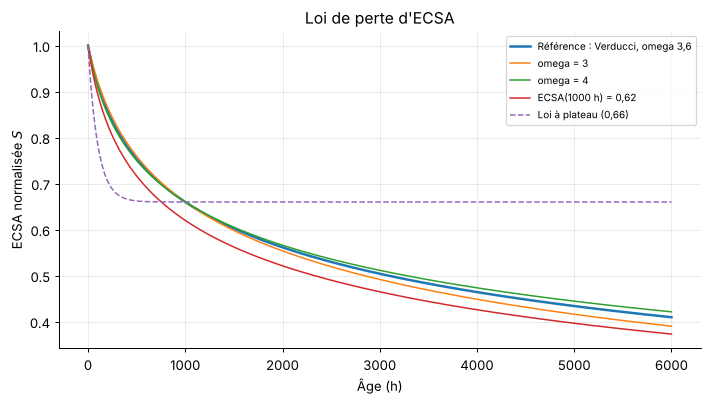

In [11]:
pm=scenarios["Moyen"]
def eol_avec_activite(fun):
    def U(I,t):
        j=I/A_GEO
        return N_CELL*(E_REV-R*T_K/(ALPHA_C*F)*np.log(j/(I0_C_0*fun(t)))-j*resistance(t,pm)+B_C*np.log(1-j/I_LIM))
    tv=brentq(lambda t:U(I_REF,t)-U_SEUIL,0,60000)
    return tv,min(tv,eol_membrane(pm))
cas_ecsa={"Référence : Verducci, omega 3,6":lambda t:activite(t,pm),
          "omega = 3":lambda t:activite(t,{**pm,"omega":3.}),
          "omega = 4":lambda t:activite(t,{**pm,"omega":4.}),
          "ECSA(1000 h) = 0,62":lambda t:activite(t,{**pm,"S1000":.62}),
          "Loi à plateau (0,66)":lambda t:.66+.34*np.exp(-np.asarray(t,float)/100.)}
lig=[]
for nom_cas,fun in cas_ecsa.items():
    tv,te=eol_avec_activite(fun)
    lig.append({"Cas":nom_cas,"ECSA_1000h":float(fun(1000.)),"ECSA_3000h":float(fun(3000.)),"ECSA_5000h":float(fun(5000.)),"EoL_tension_h":tv,"EoL_h":te})
sens_ecsa=pd.DataFrame(lig);display(sens_ecsa.round(3))
sens_ecsa.to_csv(OUT/"sensibilite_loi_ECSA.csv",index=False,encoding="utf-8-sig")
tt=np.linspace(0,6000,400);fig,ax=plt.subplots(figsize=(8,4.6))
for nom_cas,fun in cas_ecsa.items():ax.plot(tt,fun(tt),lw=2 if "Référence" in nom_cas else 1.2,ls="-" if "plateau" not in nom_cas else "--",label=nom_cas)
ax.set(xlabel="Âge (h)",ylabel="ECSA normalisée $S$",title="Loi de perte d'ECSA");ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/"06_loi_ECSA.png",dpi=220);plt.show()

## 7. Lecture des résultats

- Les durées de vie résultent des constantes publiées ; elles ne sont pas imposées. Elles se comparent à la meilleure durabilité observée sur route (4 100 h, DOE 2016) et à l'objectif DOE (8 000 h).
- La croissance du crossover est extrapolée au-delà des 1000 h de l'essai publié. La loi centrale est linéaire ; l'exponentielle (Jouin et al., 2016) et le crossover constant (Toyota) sont comparés à la section 5 bis. La loi choisie change la consommation d'hydrogène, pas la fin de vie.
- L'ECSA chute vite au début (environ 14 % en 200 h), puis continue de baisser lentement : elle n'atteint pas de plateau. Cette baisse lente, absente d'une loi à plateau, réduit la durée de vie limitée par la tension.

## 8. Limites

- La polarisation (médianes de 12 cycles de roulage, 30 à 610 A) et le profil de conduite sont mesurés sur la Mirai II du L2EP ; la température est constante (70 °C) ; la surface active de 297 cm² est l'estimation de Pielecha et Pielecha (2025, Energies 18, 5513) : 237 cm² (Mirai I) × 1,12 (128/114 kW) × 1,12 (370/330 cellules).
- Les constantes proviennent d'un essai de 1000 h sur cellule de 25 cm² (Colombo et al., 2023), extrapolé au stack et à des durées plus longues.
- L'écart d'hydrogène (192 contre 196 g) vient de deux lectures de jauge ; son origine n'est pas connue et il est gardé constant. Le crossover part d'une spécification du DOE (2 mA/cm²), pas d'une mesure.
- Aucune source ne fixe la forme de la croissance du crossover au-delà de 1 000 h ; une rupture brutale de la membrane n'est pas modélisée.
- La perte proportionnelle au courant est représentée par une résistance apparente, linéaire en temps ; elle peut inclure des effets cinétiques ou de transport non séparés.
- La loi d'ECSA est utilisée sous forme temporelle effective, calée à 1000 h, et non par cycles équivalents.
- L'ancrage point par point conserve exactement le WLTP initial mais reste une correction semi-empirique.


In [12]:
param_init.to_csv(OUT/"parametres_initiaux_70C.csv",index=False,encoding="utf-8-sig")
synthese.to_csv(OUT/"resultats_vieillissement_PEMFC_70C.csv",encoding="utf-8-sig")
for nom,q in traj.items():q.to_csv(OUT/f"trajectoire_{nom.lower()}.csv",index=False,encoding="utf-8-sig")
print("Exports terminés dans",OUT.resolve())

Exports terminés dans ./resultats_vieillissement_PEMFC_70C
